In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid", palette="Set2")

# Load dataset
df = sns.load_dataset('tips')

# Display dataset
print("First 5 rows:")
display(df.head())

print("Dataset Information:")
df.info()

print("\nDataset Shape:", df.shape)

First 5 rows:


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB

Dataset Shape: (244, 7)


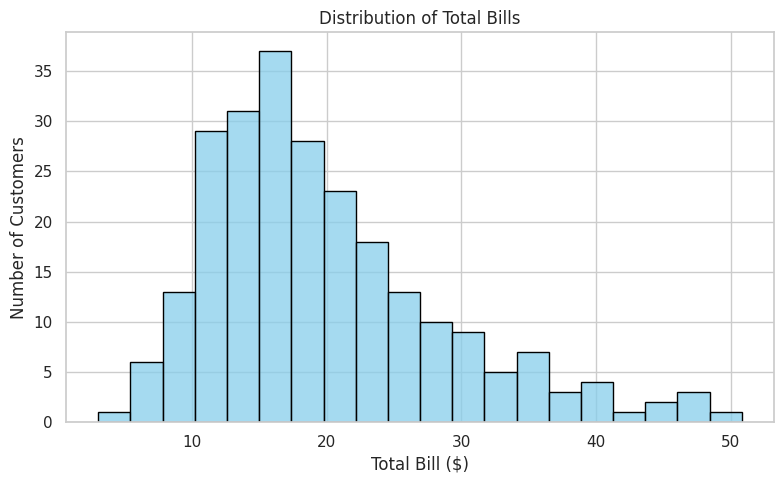

In [3]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='total_bill', bins=20,
             color='skyblue', edgecolor='black')

plt.title('Distribution of Total Bills')
plt.xlabel('Total Bill ($)')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.savefig('histogram_total_bill.png', dpi=150, bbox_inches='tight')
plt.show()

Most restaurant bills fall within the lower-to-middle bill ranges, with fewer customers having very high bills.


/tmp/ipykernel_1193/3555100928.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='day', y='tip', palette='Set2')


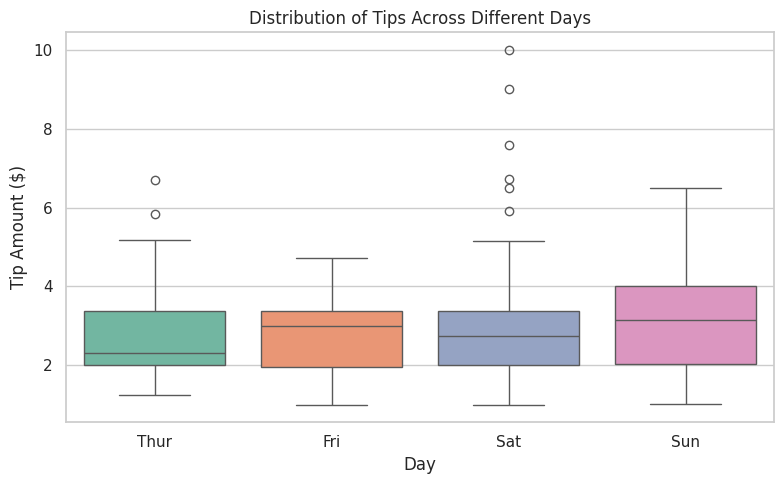

In [4]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='day', y='tip', palette='Set2')

plt.title('Distribution of Tips Across Different Days')
plt.xlabel('Day')
plt.ylabel('Tip Amount ($)')

plt.tight_layout()
plt.savefig('boxplot_tips_by_day.png', dpi=150, bbox_inches='tight')
plt.show()

Tip amounts vary across days, and some customers leave unusually high tips compared with others.

/tmp/ipykernel_1193/1432786050.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


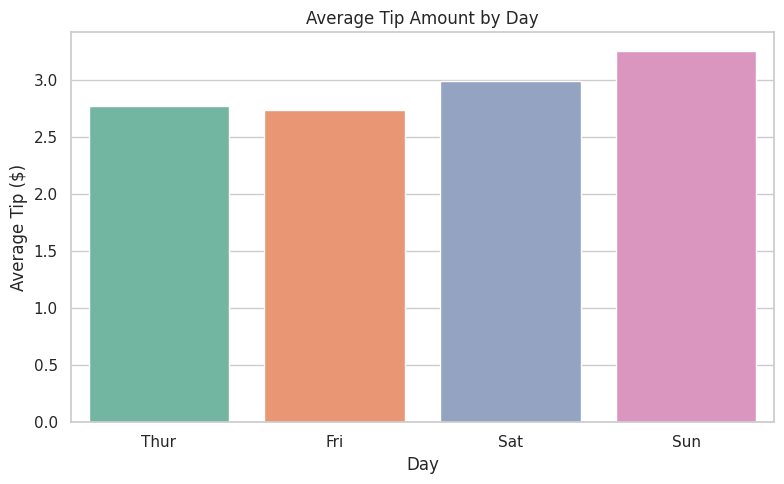

In [5]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x='day',
    y='tip',
    estimator='mean',
    errorbar=None,
    palette='Set2'
)

plt.title('Average Tip Amount by Day')
plt.xlabel('Day')
plt.ylabel('Average Tip ($)')

plt.tight_layout()
plt.savefig('barplot_average_tip.png', dpi=150, bbox_inches='tight')
plt.show()

key takeaway: The chart shows which day has the highest average tip amount.

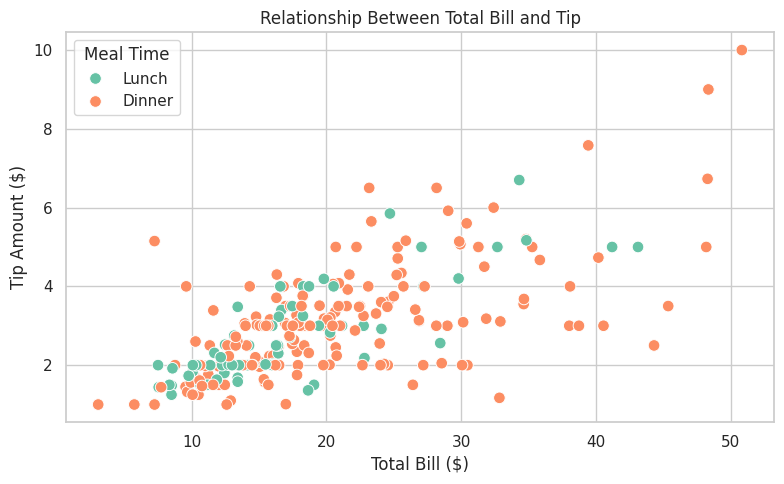

In [6]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='total_bill',
    y='tip',
    hue='time',
    palette='Set2',
    s=70
)

plt.title('Relationship Between Total Bill and Tip')
plt.xlabel('Total Bill ($)')
plt.ylabel('Tip Amount ($)')
plt.legend(title='Meal Time')

plt.tight_layout()
plt.savefig('scatterplot_bill_vs_tip.png', dpi=150, bbox_inches='tight')
plt.show()

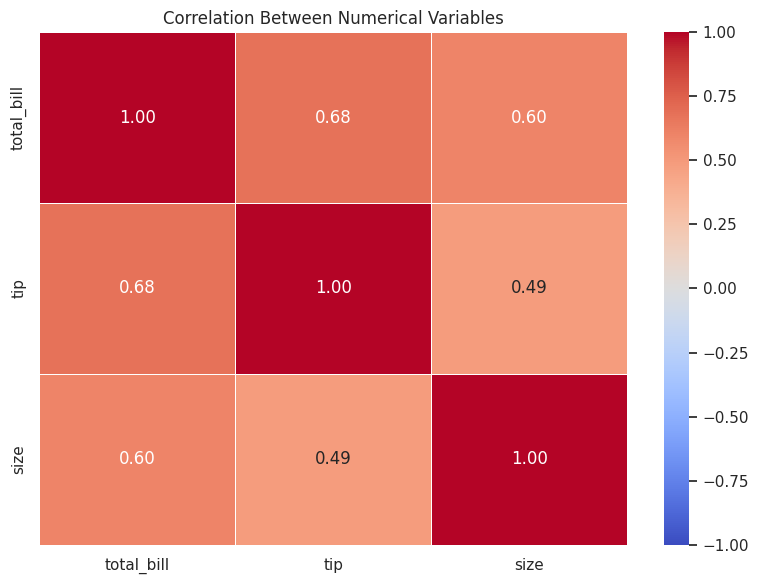

In [7]:
# Calculate correlation
correlation = df.select_dtypes(include='number').corr()

# Create heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title('Correlation Between Numerical Variables')

plt.tight_layout()
plt.savefig('correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

key takeaway: Total bill and tip have the strongest positive correlation (0.68), suggesting that customers generally leave higher tips when their bills are higher.

/tmp/ipykernel_1193/459830942.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='day', y='tip',
/tmp/ipykernel_1193/459830942.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='day', y='tip',


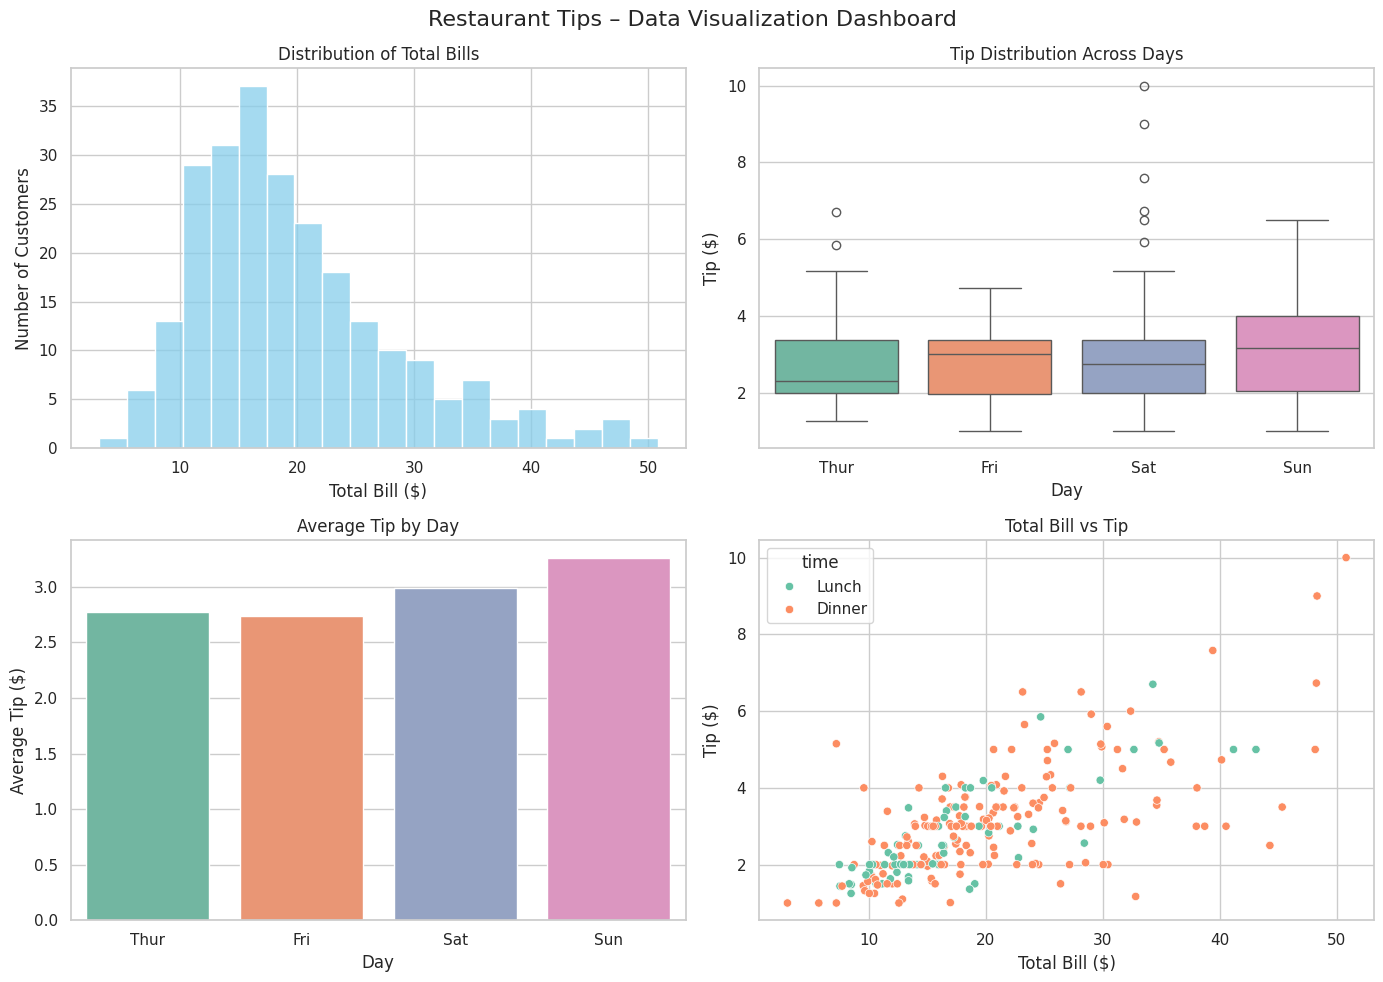

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Histogram
sns.histplot(data=df, x='total_bill', bins=20,
             color='skyblue', ax=axes[0, 0])
axes[0, 0].set_title('Distribution of Total Bills')
axes[0, 0].set_xlabel('Total Bill ($)')
axes[0, 0].set_ylabel('Number of Customers')

# Box Plot
sns.boxplot(data=df, x='day', y='tip',
            palette='Set2', ax=axes[0, 1])
axes[0, 1].set_title('Tip Distribution Across Days')
axes[0, 1].set_xlabel('Day')
axes[0, 1].set_ylabel('Tip ($)')

# Bar Chart
sns.barplot(data=df, x='day', y='tip',
            estimator='mean', errorbar=None,
            palette='Set2', ax=axes[1, 0])
axes[1, 0].set_title('Average Tip by Day')
axes[1, 0].set_xlabel('Day')
axes[1, 0].set_ylabel('Average Tip ($)')

# Scatter Plot
sns.scatterplot(data=df, x='total_bill', y='tip',
                hue='time', palette='Set2',
                ax=axes[1, 1])
axes[1, 1].set_title('Total Bill vs Tip')
axes[1, 1].set_xlabel('Total Bill ($)')
axes[1, 1].set_ylabel('Tip ($)')

plt.suptitle('Restaurant Tips – Data Visualization Dashboard',
             fontsize=16)

plt.tight_layout()
plt.savefig('tips_visualization_dashboard.png',
            dpi=150, bbox_inches='tight')
plt.show()

Chart Takeaways
1. Histogram: Most restaurant bills are concentrated in the lower-to-middle price ranges.
2. Box Plot: Tip amounts vary across different days, with some unusually high values.
3. Bar Chart: Sunday has the highest average tip, while Friday has the lowest.
4. Scatter Plot: Higher total bills generally tend to be associated with higher tips.
5. Correlation Heatmap: Total bill and tip have the strongest positive correlation (0.68).